# Guía interactiva · Predecir cancelaciones en el Hotel Valle de Cocora
**Programación Aplicada · Universidad de La Sabana**  ·  Recurso para estudiantes y pares académicos

Esta guía recorre el análisis desde los datos crudos hasta tres decisiones de negocio. En cada paso hay:

- qué se hace y por qué,
- el código, para ejecutarlo celda por celda,
- cómo leer el resultado,
- al final de cada bloque, preguntas para pensar y, en varios, controles interactivos para mover un parámetro y ver cómo cambia la decisión.

### El caso en 30 segundos
El Hotel Valle de Cocora (38 habitaciones, Eje Cafetero) pierde ingresos porque **una de cada cinco reservas se cancela**: la habitación queda vacía y ya se rechazaron otros huéspedes. La gerencia quiere decidir:

| # | Decisión | Pregunta que la guía responde con datos |
|---|---|---|
| P1 | ¿Cuántas **reservas adicionales** aceptar por encima de la capacidad (la «sobreventa controlada»)? | ¿Se puede anticipar cuántas reservas se cancelarán cada noche? |
| P2 | ¿A **quién** pedirle pago por adelantado? | ¿Qué clientes cancelan más y cuánto se ahorra si solo a ellos se les pide depósito? |
| P3 | ¿Cómo ajustar las **políticas por canal** (Booking, Airbnb)? | ¿Cuánto baja la cancelación si las reservas Flexibles pasan a Moderada o pagan depósito? |

### Ruta de la guía
1. Configurar y cargar datos → 2. Preparar los datos → 3. Mirar antes de modelar → 4. Modelo de probabilidad → 5. P1 → 6. P2 → 7. P3 → 8. Ejercicios y glosario

**Requisitos:** Python 3.10+, `pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn` y (opcional, para los controles) `ipywidgets`. El archivo `hotel_reservas.csv` está en la carpeta `datos/` del repositorio.
**Tiempo estimado:** 45–60 minutos.

## 1. Configuración y carga de datos
Qué hacemos: importar las librerías, fijar parámetros y leer el CSV.
**Por qué:** dejar los parámetros (semilla, fechas de corte) en un solo lugar hace que el análisis sea **reproducible**: otra persona obtiene exactamente tus cifras.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
import seaborn as sns
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import roc_auc_score

sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
AZUL, ROJO, GRIS, VERDE, NARANJA = "#2563eb", "#dc2626", "#9ca3af", "#16a34a", "#f59e0b"

SEMILLA = 42                                  # fija el azar: mismos resultados cada vez
INI_VENTANA = pd.Timestamp("2023-05-01")      # antes de esta fecha el historial está incompleto
FIN_VENTANA = pd.Timestamp("2025-06-18")      # última fecha de reserva registrada
CORTE_TEST = pd.Timestamp("2024-07-01")       # entrenamos con lo anterior y evaluamos con lo posterior
rng = np.random.default_rng(SEMILLA)

pct = lambda ax, e="y": (ax.yaxis if e == "y" else ax.xaxis).set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
M = lambda x: f"${x/1e6:,.0f} M"              # formatea pesos en millones

raw = pd.read_csv("../../datos/hotel_reservas.csv", parse_dates=["fecha_reserva", "fecha_llegada"])
print(f"{raw.shape[0]:,} filas × {raw.shape[1]} columnas")
raw.head(3)

100,300 filas × 20 columnas


,id_reserva,fecha_reserva,anticipacion_dias,fecha_llegada,mes_llegada,noches,adultos,ninos,tipo_habitacion,canal,pais_origen,tarifa_noche,politica_cancelacion,deposito_pagado,huesped_recurrente,solicitudes_especiales,cancelaciones_previas,incluye_desayuno,cancelada,ingreso_total
0,32834,2024-05-04,68,2024-07-11,7,3,4,0,Doble,Agencia,Colombia,295000.0,No reembolsable,1,0,1,0,0,0,885000.0
1,93669,2024-06-02,29,2024-07-01,7,2,3,0,Doble,Directo web,Colombia,240000.0,Flexible,1,0,0,0,1,0,480000.0
2,30892,2023-02-07,70,2023-04-18,4,2,2,1,Familiar,Directo web,Otros,317000.0,Moderada,0,0,0,0,0,0,634000.0


**Diccionario esencial.** Cada fila es una reserva. Las columnas que más usaremos:

| Columna | Significado |
|---|---|
| `cancelada` | **Lo que queremos explicar**: 1 si la reserva se canceló, 0 si el huésped llegó |
| `anticipacion_dias` | Días entre reservar y llegar |
| `politica_cancelacion` | Flexible, Moderada o No reembolsable |
| `deposito_pagado` | 1 si pagó por adelantado |
| `canal` | Booking, Airbnb, Directo web, … |
| `cancelaciones_previas` | Veces que ese huésped canceló antes |
| `tarifa_noche`, `noches` | Con ellas se calcula el ingreso en juego |

Trampa a evitar: `ingreso_total` vale **0 cuando la reserva se cancela**. Si lo usáramos para predecir, el modelo quedaría con la respuesta incluida (lo llamamos *fuga de información*). Por eso queda fuera.

Para pensar: ¿qué otra columna podría «delatar» la respuesta si se registrara después de la cancelación?

## 2. Preparar los datos
Qué hacemos: (1) eliminar filas duplicadas, (2) tratar los faltantes, (3) crear el ingreso en juego y (4) quedarnos con una **ventana temporal confiable**.

**Por qué cada decisión:**
- *Duplicados:* son la misma reserva registrada dos veces; contarlos inflaría cancelaciones e ingresos.
- *Faltantes en `canal` y `pais_origen` (~4 %):* no los inventamos ni los borramos; los dejamos como categoría **«No registrado»**.
- *Ventana:* el historial empieza en enero de 2023 (al inicio solo aparecen reservas hechas con poca anticipación, que cancelan menos) y termina el 18-jun-2025 (al final solo hay reservas muy anticipadas, que cancelan más). Ambos bordes **distorsionan** las series de tiempo; los excluimos al modelar.

In [2]:
df = raw.drop_duplicates().copy()                                   # 1) sin duplicados
df[["canal", "pais_origen"]] = df[["canal", "pais_origen"]].fillna("No registrado")   # 2) faltantes como categoría
df["ingreso_potencial"] = df.tarifa_noche * df.noches               # 3) cuánto se ganaría si el huésped llega
df["ingreso_perdido"] = df.ingreso_potencial * df.cancelada         #    y cuánto se pierde si cancela
dv = df[df.fecha_llegada.between(INI_VENTANA, FIN_VENTANA)].copy().reset_index(drop=True)   # 4) ventana confiable
es_tr = dv.fecha_llegada < CORTE_TEST                               # True = entrenamiento, False = prueba

print(f"Duplicados eliminados: {len(raw) - len(df):,} | reservas únicas: {len(df):,} | en la ventana: {len(dv):,}")
print(f"Entrenamiento: {es_tr.sum():,} reservas (antes de jul-2024) | Prueba: {(~es_tr).sum():,} (jul-2024 → 18-jun-2025)")

Duplicados eliminados: 300 | reservas únicas: 100,000 | en la ventana: 86,168
Entrenamiento: 47,018 reservas (antes de jul-2024) | Prueba: 39,150 (jul-2024 → 18-jun-2025)


Cómo leerlo:** quedan ~100.000 reservas únicas; usamos ~86.000 para modelar. **Separar entrenamiento y prueba por fecha** (no al azar) es clave: así evaluamos al modelo como se usaría en la vida real, prediciendo un futuro que no ha visto.

## 3. Mirar antes de modelar
Qué hacemos: calcular la tasa de cancelación global y por los factores más relevantes.
**Por qué:** el modelo solo es creíble si primero entendemos qué patrones hay en los datos.

Tasa de cancelación global: 19.0%  |  ingreso perdido: $15,511 M de $81,694 M


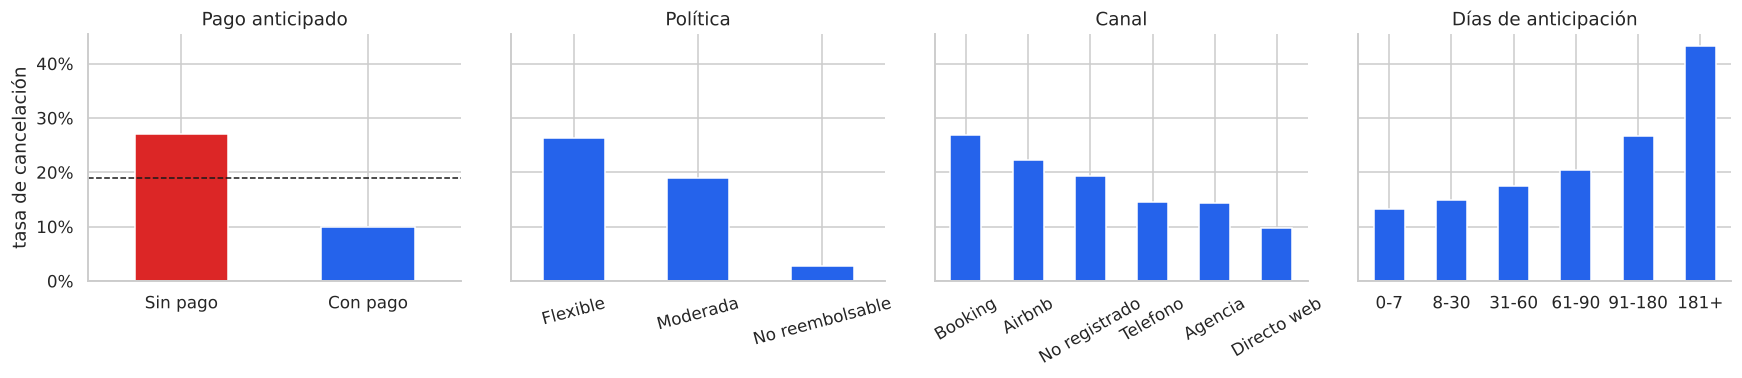

In [3]:
print(f"Tasa de cancelación global: {df.cancelada.mean():.1%}  |  ingreso perdido: {M(df.ingreso_perdido.sum())} de {M(df.ingreso_potencial.sum())}")

fig, ax = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
df.groupby("deposito_pagado").cancelada.mean().rename({0: "Sin pago", 1: "Con pago"}).plot.bar(ax=ax[0], color=[ROJO, AZUL], rot=0, title="Pago anticipado")
df.groupby("politica_cancelacion").cancelada.mean().sort_values(ascending=False).plot.bar(ax=ax[1], color=AZUL, rot=15, title="Política")
df.groupby("canal").cancelada.mean().sort_values(ascending=False).plot.bar(ax=ax[2], color=AZUL, rot=30, title="Canal")
df.groupby(pd.cut(df.anticipacion_dias, [-1, 7, 30, 60, 90, 180, 366], labels=["0-7", "8-30", "31-60", "61-90", "91-180", "181+"])).cancelada.mean().plot.bar(ax=ax[3], color=AZUL, rot=0, title="Días de anticipación")
for a in ax: pct(a); a.set_xlabel("")
ax[0].axhline(df.cancelada.mean(), color="k", ls="--", lw=1); ax[0].set_ylabel("tasa de cancelación")
plt.tight_layout(); plt.show()

Cómo leerlo (la línea punteada es el promedio):**
- Sin pago anticipado se cancela ~27 %; con pago, ~10 %. **Pero cuidado:** casi toda la tarifa *No reembolsable* ya viene con depósito, y esa tarifa casi no cancela. Si comparamos solo dentro de *Flexible* y *Moderada*, la diferencia es de ≈1,9 veces, no ≈2,7.
- A más anticipación, más cancelación (de ~13 % en reservas de última hora a ~43 % en reservas de más de 6 meses).
- Booking y Airbnb cancelan más que la venta directa.

Para pensar: ¿por qué comparar «con vs. sin depósito» sin controlar por política exagera el efecto? (Pista: ¿quién elige la tarifa No reembolsable?)

## 4. Un modelo que da una probabilidad por reserva
Qué hacemos: entrenar un *gradient boosting* que, para cada reserva, devuelve la **probabilidad de que se cancele**, usando solo lo que se sabe al momento de reservar.
**Por qué probabilidades y no un «sí/no»:** las tres decisiones las necesitan. P1 las **suma** para estimar cuántas cancelaciones habrá; P2 las **compara con un umbral** para decidir a quién pedir depósito; P3 las usa para simular políticas.

**Idea intuitiva del modelo:** un conjunto de muchos árboles de decisión pequeños, cada uno corrige los errores del anterior (p. ej., «si anticipó más de 90 días *y* es Flexible *y* no pagó → riesgo alto»).

In [4]:
feats_cat = ["tipo_habitacion", "canal", "pais_origen", "politica_cancelacion"]
feats_num = ["anticipacion_dias", "noches", "adultos", "ninos", "tarifa_noche", "deposito_pagado", "huesped_recurrente",
             "solicitudes_especiales", "cancelaciones_previas", "incluye_desayuno", "mes_llegada"]
enc = OrdinalEncoder().fit(dv[feats_cat])          # convierte categorías (texto) en números enteros

def matriz(d):
    X = d[feats_cat + feats_num].copy()
    X[feats_cat] = enc.transform(d[feats_cat]).astype(int)
    return X

modelo = HistGradientBoostingClassifier(max_iter=200, learning_rate=.08, random_state=SEMILLA,
                                        categorical_features=[list(feats_cat + feats_num).index(c) for c in feats_cat])
modelo.fit(matriz(dv[es_tr]), dv.cancelada[es_tr])       # aprende SOLO del periodo de entrenamiento
dv["p"] = modelo.predict_proba(matriz(dv))[:, 1]         # probabilidad de cancelar de cada reserva
te = dv[~es_tr].copy()                                    # año de prueba (el modelo nunca lo vio al entrenar)

print(f"AUC en prueba: {roc_auc_score(te.cancelada, te.p):.3f}   (0,5 = azar · 1,0 = perfecto)")
print(f"Cancelaciones reales en prueba: {te.cancelada.sum():,} | suma de probabilidades: {te.p.sum():,.0f}")

AUC en prueba: 0.770   (0,5 = azar · 1,0 = perfecto)
Cancelaciones reales en prueba: 7,420 | suma de probabilidades: 7,455


Cómo leerlo:**
- **AUC ≈ 0,77:** si tomas una reserva que canceló y otra que no, el modelo asigna mayor probabilidad a la que canceló el 77 % de las veces. Es una señal real, aunque no perfecta.
- **La suma de probabilidades (~7.450) es casi igual a las cancelaciones reales (~7.420):** esto es lo que usaremos en P1.

Antes de seguir conviene revisar algo más importante que el AUC: ¿el modelo está **calibrado**? Si dice 30 %, ¿cancela ≈ 30 %?

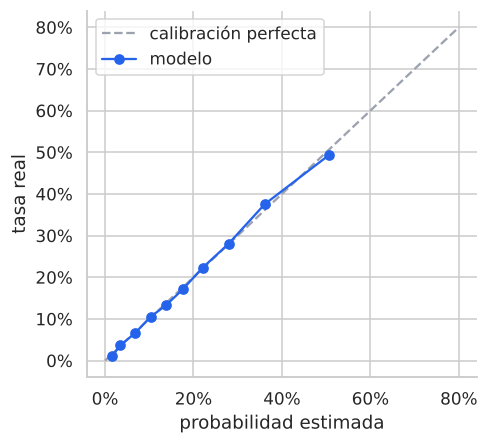

In [5]:
te["decil"] = pd.qcut(te.p, 10, labels=False, duplicates="drop")       # 10 grupos de igual tamaño, de menor a mayor riesgo
cal = te.groupby("decil").agg(p_media=("p", "mean"), tasa_real=("cancelada", "mean"))
fig, ax = plt.subplots(figsize=(4.6, 4.2))
ax.plot([0, .8], [0, .8], "--", color=GRIS, label="calibración perfecta"); ax.plot(cal.p_media, cal.tasa_real, "o-", color=AZUL, label="modelo")
ax.set_xlabel("probabilidad estimada"); ax.set_ylabel("tasa real"); pct(ax); pct(ax, "x"); ax.legend(); plt.tight_layout(); plt.show()

Cómo leerlo:** los puntos casi sobre la diagonal significan que las probabilidades son confiables; podemos sumarlas y compararlas con umbrales sin sorpresas.

Para pensar: ¿qué pasaría con P1 si el modelo siempre sobreestimara el riesgo? (Pista: reservas adicionales de más.)

## 5. P1 · ¿Cuántas reservas adicionales aceptar?
Idea: cada noche hay un número **incierto** de cancelaciones. Simulamos muchas versiones de esa noche (cada reserva cancela con su probabilidad) y miramos la distribución. Aceptamos como reservas adicionales el **percentil *q***: con probabilidad 1 − *q* se cancelarán **al menos** tantas, y las reservas adicionales encontrarán habitación.

**Unidad de análisis:** la **noche de llegada** (cada reserva se cuenta en la noche en que debe llegar).

### 5.1 Una sola noche, paso a paso

Noche 2025-03-15: 117 reservas programadas · cancelaciones reales: 22 · esperadas por el modelo: 23.7


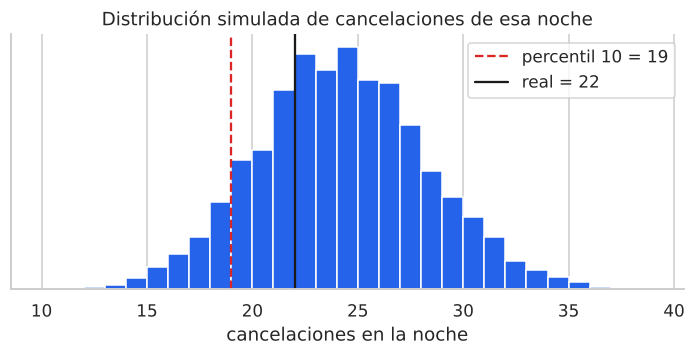

In [6]:
noche = te.fecha_llegada.dt.normalize().value_counts().index[100]          # una noche cualquiera del año de prueba
g = te[te.fecha_llegada.dt.normalize() == noche]
print(f"Noche {noche.date()}: {len(g)} reservas programadas · cancelaciones reales: {int(g.cancelada.sum())} · esperadas por el modelo: {g.p.sum():.1f}")

NSIM = 4000
sims = (rng.random((NSIM, len(g))) < g.p.values).sum(axis=1)               # 4.000 noches simuladas: cada reserva cancela con su prob.
p10 = int(np.quantile(sims, .10, method="lower"))
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.hist(sims, bins=range(sims.min(), sims.max() + 2), color=AZUL, edgecolor="white", density=True)
ax.axvline(p10, color=ROJO, ls="--", label=f"percentil 10 = {p10}"); ax.axvline(g.cancelada.sum(), color="k", label=f"real = {int(g.cancelada.sum())}")
ax.set_xlabel("cancelaciones en la noche"); ax.set_yticks([]); ax.legend(); ax.set_title("Distribución simulada de cancelaciones de esa noche"); plt.tight_layout(); plt.show()

Cómo leerlo:** la barra roja es el número que casi seguro se superará (con 90 % de probabilidad hay *al menos* esas cancelaciones). Si aceptamos ese número de reservas adicionales, es muy probable que todas encuentren cuarto. La línea negra es lo que realmente pasó.

### 5.2 Las 353 noches del año de prueba
Medimos tres cosas (definiciones del proyecto):
- **Cobertura** = cancelaciones cubiertas por reservas adicionales ÷ cancelaciones totales (qué parte del hueco logramos llenar).
- **Incidencia** = % de noches en que aceptamos más reservas adicionales que cancelaciones reales (algún huésped se queda sin cuarto).
- **MAE** = error medio entre cancelaciones esperadas y reales por noche.

In [7]:
def colchon(ps, q):
    s = (rng.random((NSIM, len(ps))) < ps).sum(axis=1)
    return int(np.quantile(s, q, method="lower"))

grupos = list(te.groupby(te.fecha_llegada.dt.normalize()))
n1 = pd.DataFrame({"reservas": [len(g) for _, g in grupos], "reales": [int(g.cancelada.sum()) for _, g in grupos],
                   "esperadas": [g.p.sum() for _, g in grupos]}, index=[f for f, _ in grupos])

def evaluar(q):
    extra = np.array([colchon(g.p.values, q) for _, g in grupos])
    return dict(percentil=f"P{q:.0%}", extra_media=extra.mean(), cobertura=np.minimum(extra, n1.reales).sum() / n1.reales.sum(), incidencia=(extra > n1.reales).mean())

tabla = pd.DataFrame([evaluar(q) for q in (.02, .05, .10, .20, .30)])
display(tabla.style.format({"extra_media": "{:.1f}", "cobertura": "{:.1%}", "incidencia": "{:.1%}"}))
print(f"MAE del pronóstico por noche: {np.abs(n1.esperadas - n1.reales).mean():.2f} cancelaciones")

,percentil,extra_media,cobertura,incidencia
0,P2%,13.6,64.5%,1.4%
1,P5%,15.0,71.1%,3.7%
2,P10%,16.3,76.7%,7.6%
3,P20%,17.9,83.1%,16.7%
4,P30%,19.0,87.3%,27.5%


MAE del pronóstico por noche: 3.07 cancelaciones


Cómo leerlo:** es un **compromiso**. Un percentil más alto acepta más reservas adicionales → más cobertura, pero más noches con incidencia. Las metas del proyecto son **cobertura ≥ 70 %** e **incidencia < 6 %**:
- **P10** supera la cobertura (~77 %) pero queda un poco por encima del 6 % de incidencia (~7,6 %).
- **P5** cumple ambas (~71 % y ~4 %).

### 5.3 Controla el percentil

In [8]:
def p1_interactivo(percentil=10):
    r = evaluar(percentil / 100)
    ok_c, ok_i = r["cobertura"] >= .70, r["incidencia"] < .06
    print(f"Percentil {percentil}: ~{r['extra_media']:.1f} reservas adicionales por noche · cobertura {r['cobertura']:.1%} {'cumple' if ok_c else 'no cumple'} (meta ≥ 70 %) · incidencia {r['incidencia']:.1%} {'cumple' if ok_i else 'no cumple'} (meta < 6 %)")

try:
    from ipywidgets import interact, IntSlider
    interact(p1_interactivo, percentil=IntSlider(value=10, min=1, max=40, step=1, description="percentil"))
except ImportError:
    p1_interactivo(10)       # sin ipywidgets: se muestra el valor por defecto; cambia el número y vuelve a ejecutar

interactive(children=(IntSlider(value=10, description='percentil', max=40, min=1), Output()), _dom_classes=('w…

Ejercicios: (1) Encuentra el percentil más alto que aún cumple la meta de incidencia. (2) ¿Qué le dirías a la gerencia si prefiere «cero riesgo de dejar a un huésped sin cuarto»? (3) Compara con una regla sin modelo (la misma probabilidad para todas las reservas): ¿cuánto aporta el modelo en este problema? *(Respuesta del equipo: poco; el conteo por noche ya está cerca de su piso de ruido, el valor del modelo aparece sobre todo en P2.)*

## 6. P2 · ¿A quién pedirle pago por adelantado?
Idea: pedir depósito a todos espanta clientes; pedirlo solo a quienes tienen **alta probabilidad de cancelar** protege ingreso con poco costo. Decidimos con un **umbral** de probabilidad.

**Cómo estimamos el ahorro sin inflarlo:**
1. Medimos el efecto del depósito **dentro de Flexible y Moderada** y **solo con datos de entrenamiento**: la cancelación con depósito es una fracción *r* de la de sin depósito.
2. *Ingreso protegido* = ingreso perdido por las reservas marcadas × (1 − *r*).
3. *Costo:* una fracción *g* de las marcadas **desiste** al exigirles pago; se pierde el ingreso de las que sí se habrían quedado.

Ojo: el efecto del depósito es una **asociación observada**, no una causa probada: por eso probamos también mitad y cuarto del efecto.

In [9]:
fm = dv[es_tr & dv.politica_cancelacion.isin(["Flexible", "Moderada"])]
r = fm[fm.deposito_pagado == 1].cancelada.mean() / fm[fm.deposito_pagado == 0].cancelada.mean()
print(f"Factor r = {r:.2f}  → con depósito se cancela ~{r:.0%} de lo que se cancela sin depósito (Flexible + Moderada, entrenamiento)")

sin = te[te.deposito_pagado == 0]                                    # reservas del año de prueba que no pagaron por adelantado
recuperable = sin.ingreso_perdido.sum() * (1 - r)                    # techo: si se exigiera depósito a TODAS

def p2(umbral=.30, g=.05, efecto=1.0):
    f = sin[sin.p > umbral]                                          # reservas marcadas como alto riesgo
    protegido = f.ingreso_perdido.sum() * (1 - r) * efecto
    costo = g * (f.ingreso_potencial * (1 - f.cancelada)).sum()      # ingreso que se pierde por quienes desisten
    return dict(marcadas=len(f), pct_marcadas=len(f) / len(sin), tasa_real=f.cancelada.mean(), protegido=protegido,
                pct_recuperable=protegido / (recuperable * efecto), neto=protegido - costo)

tabla = pd.DataFrame([dict(umbral=u, **p2(u)) for u in (.10, .20, .30, .40, .50)])
display(tabla.assign(protegido=tabla.protegido.map(M), neto=tabla.neto.map(M)).style.format(
    {"umbral": "{:.0%}", "marcadas": "{:,.0f}", "pct_marcadas": "{:.0%}", "tasa_real": "{:.1%}", "pct_recuperable": "{:.0%}"}))

Factor r = 0.53  → con depósito se cancela ~53% de lo que se cancela sin depósito (Flexible + Moderada, entrenamiento)


,umbral,marcadas,pct_marcadas,tasa_real,protegido,pct_recuperable,neto
0,10%,"18,924",91%,28.9%,"$2,104 M",98%,"$1,551 M"
1,20%,"12,773",62%,35.9%,"$1,758 M",82%,"$1,420 M"
2,30%,"7,670",37%,42.8%,"$1,266 M",59%,"$1,086 M"
3,40%,"3,853",19%,49.2%,$730 M,34%,$649 M
4,50%,"1,479",7%,56.2%,$329 M,15%,$302 M


Cómo leerlo:** con umbral 30 %, se marca ≈37 % de las reservas sin pago; esas cancelan ≈43 % (frente a ≈18 % en el resto) y concentran ≈59 % del ingreso recuperable. **Focalizar rinde:** con poco más de un tercio de las reservas se captura casi 60 % del beneficio posible.

### 6.1 Controla el umbral, el desistimiento y la fuerza del efecto

In [10]:
def p2_interactivo(umbral=30, desisten=5, efecto=100):
    x = p2(umbral / 100, desisten / 100, efecto / 100)
    print(f"Umbral {umbral} %: se exige depósito a {x['marcadas']:,} reservas ({x['pct_marcadas']:.0%} de las que no pagan), que cancelan {x['tasa_real']:.1%}")
    print(f"  Ingreso protegido: {M(x['protegido'])}  ·  beneficio neto si desisten {desisten} %: {M(x['neto'])}")

try:
    from ipywidgets import interact, IntSlider
    interact(p2_interactivo, umbral=IntSlider(value=30, min=5, max=70, step=5), desisten=IntSlider(value=5, min=0, max=30, step=1),
             efecto=IntSlider(value=100, min=25, max=100, step=25, description="% del efecto"))
except ImportError:
    p2_interactivo()

interactive(children=(IntSlider(value=30, description='umbral', max=70, min=5, step=5), IntSlider(value=5, des…

Ejercicios: (1) ¿A partir de qué porcentaje de desistimiento deja de convenir el umbral de 30 %? (2) Con solo el 50 % del efecto observado, ¿qué umbral recomendarías? (3) ¿Por qué un umbral muy bajo puede dar el mayor beneficio en el papel pero ser mala idea comercial?

## 7. P3 · Políticas por canal (Booking y Airbnb)
Idea: en cada canal, las reservas **Flexibles sin depósito** son las más volátiles. Simulamos que pasen a **Moderada** o **paguen depósito**, aplicando la tasa observada de esa «celda» (canal × política × depósito).

**Punto de equilibrio:** si por endurecer la política se pierde más de *g\** de las reservas afectadas, las estancias confirmadas **bajan** en lugar de subir:

$$g^* = 1 - \frac{1 - p_{hoy}}{1 - p_{nueva}}$$

Es un **techo optimista**: supone que la demanda no cambia. El tope razonable de pérdida de volumen para un piloto es menor que *g\**.

In [11]:
celdas = dv.groupby(["canal", "politica_cancelacion", "deposito_pagado"]).cancelada.mean()
filas = []
for canal in ("Booking", "Airbnb"):
    p_hoy = celdas[(canal, "Flexible", 0)]
    for nombre, clave in (("Flexible → Moderada", (canal, "Moderada", 0)), ("Flexible + depósito", (canal, "Flexible", 1))):
        p_nueva = celdas[clave]
        n_c = (df.canal == canal).sum(); n_af = ((df.canal == canal) & (df.politica_cancelacion == "Flexible") & (df.deposito_pagado == 0)).sum()
        tasa_canal = df[df.canal == canal].cancelada.mean()
        filas.append(dict(canal=canal, escenario=nombre, flex_hoy=p_hoy, flex_nueva=p_nueva, canal_hoy=tasa_canal,
                          canal_nueva=tasa_canal - n_af / n_c * (p_hoy - p_nueva), equilibrio=1 - (1 - p_hoy) / (1 - p_nueva)))
p3 = pd.DataFrame(filas)
display(p3.style.format({c: "{:.1%}" for c in p3.columns if c not in ("canal", "escenario")}))

,canal,escenario,flex_hoy,flex_nueva,canal_hoy,canal_nueva,equilibrio
0,Booking,Flexible → Moderada,43.5%,32.4%,26.9%,23.6%,16.5%
1,Booking,Flexible + depósito,43.5%,24.7%,26.9%,21.4%,25.0%
2,Airbnb,Flexible → Moderada,36.6%,26.1%,22.3%,19.2%,14.2%
3,Airbnb,Flexible + depósito,36.6%,20.3%,22.3%,17.4%,20.5%


Cómo leerlo:** en Booking la tasa pasaría de ≈26,9 % a ≈23,6 % (Moderada) o ≈21,4 % (depósito); en Airbnb de ≈22,3 % a ≈19,2 % o ≈17,4 %. La columna *equilibrio* indica cuánta demanda se puede perder antes de que el cambio deje de convenir (≈25 % en Booking con depósito).

### 7.1 Prueba cuánta demanda se perdería

In [12]:
def p3_interactivo(canal="Booking", escenario="Flexible + depósito", perdida=10):
    x = p3[(p3.canal == canal) & (p3.escenario == escenario)].iloc[0]
    g = perdida / 100
    cambio = (1 - g) * (1 - x.flex_nueva) - (1 - x.flex_hoy)       # variación de estancias confirmadas por reserva afectada
    veredicto = "las estancias confirmadas suben" if cambio > 0 else "las estancias confirmadas bajan"
    print(f"{canal} · {escenario} · si se pierde {perdida} % de las reservas afectadas: {veredicto} ({cambio:+.1%} por reserva afectada). Equilibrio en {x.equilibrio:.1%}.")

try:
    from ipywidgets import interact, IntSlider, Dropdown
    interact(p3_interactivo, canal=Dropdown(options=["Booking", "Airbnb"]), escenario=Dropdown(options=["Flexible → Moderada", "Flexible + depósito"]),
             perdida=IntSlider(value=10, min=0, max=40, step=1, description="% se pierde"))
except ImportError:
    p3_interactivo()

interactive(children=(Dropdown(description='canal', options=('Booking', 'Airbnb'), value='Booking'), Dropdown(…

Ejercicios: (1) ¿Por qué el piloto debe fijar un tope **por debajo** del punto de equilibrio y no justo en él? (2) La mezcla de políticas es casi igual en todos los canales, pero Booking cancela más. ¿Qué implica sobre si el problema es «la política» o «el canal»?

## 8. Cierre
### Qué aprendiste
| Decisión | Resultado clave | Cómo se obtuvo |
|---|---|---|
| **P1** | Con el percentil 5–10 se aceptan ~15–16 reservas adicionales por noche; P5 cumple ambas metas, P10 queda levemente por encima del 6 % de incidencia | Simulación de cancelaciones noche a noche con probabilidades calibradas |
| **P2** | Exigir depósito al ≈37 % de las reservas sin pago (p > 30 %) protege ≈59 % del ingreso recuperable | Umbral sobre la probabilidad + factor *r* medido dentro de la política |
| **P3** | Booking baja a ≈21–24 % y Airbnb a ≈17–19 %; el equilibrio de demanda en Booking con depósito es ≈25 % | Tasas por celda canal × política × depósito |

### Límites que debes recordar
1. **Asociación ≠ causalidad:** el efecto del depósito y de la política viene de datos observados; el **piloto** es quien lo confirma.
2. **Sin fecha de cancelación:** sabemos *si* se canceló, no *cuándo*; asumimos que se conoce antes de la llegada.
3. **Escala:** los datos equivalen a ≈8 veces las 38 habitaciones; lee las cifras como **proporciones**.
4. **Promoción de 2023:** no se ve en los datos; el modelo rinde igual sin ese año (AUC 0,768 vs 0,770).

### Glosario
- **AUC:** capacidad del modelo de ordenar reservas por riesgo (0,5 = azar, 1 = perfecto).
- **Calibración:** que una probabilidad de 30 % corresponda a ≈30 % de cancelaciones reales.
- **Percentil 10:** valor que se supera el 90 % de las veces.
- **Cobertura / incidencia:** parte del hueco que se llena / noches con más llegadas que cuartos.
- **Fuga de información:** usar como predictor algo que solo se conoce después del evento.
- **Punto de equilibrio (g\*):** pérdida de demanda a la cual una política deja de convenir.

### Autoevaluación
1. ¿Por qué separamos entrenamiento y prueba por fecha y no al azar?
2. ¿Qué diferencia hay entre «cancelaciones esperadas» y «reservas adicionales a aceptar»?
3. Si el desistimiento por pedir depósito fuera 25 %, ¿qué cambiaría en P2?
4. ¿Qué evidencia necesitarías para afirmar que el depósito *causa* menos cancelaciones?